# Rwanda AgriAgronomist Climate Assist (RACA)
## AI-Based Crop Disease Detection for Climate-Resilient Agriculture

**Author:** Honore Harerimana  
**Role:** Machine Learning & Software Developer  
**Organization:** Rwanda AgriAgronomist Climate Assist (Youth-Led Initiative)

---

## Project Overview

This notebook is part of the **Rwanda AgriAgronomist Climate Assist (RACA)** project — a youth-led, AI-driven initiative aimed at improving climate resilience among smallholder farmers in Rwanda.

The goal of this component is to develop a **computer vision model** capable of accurately identifying crop diseases at early stages, enabling timely intervention and reducing climate-related agricultural losses.

This work supports climate adaptation by strengthening farmers’ capacity to respond to increasing disease prevalence caused by climate variability.

---

## Problem Statement

Climate change has intensified:
- Crop disease outbreaks
- Yield losses among smallholder farmers
- Limited access to early diagnostic tools in rural communities

Most farmers lack fast, affordable, and reliable mechanisms to identify crop diseases before significant damage occurs. This leads to delayed treatment, food insecurity, and economic loss.

---

## Solution Approach

This notebook focuses on:
- Training a **Convolutional Neural Network (CNN)** for crop disease classification
- Applying **transfer learning** to improve performance with limited local data
- Using **data augmentation** to enhance model robustness
- Specializing on priority crops:
  - Maize
  - Beans
  - Potatoes

The trained model will later be integrated into a web and mobile-based platform that connects farmers with agronomists, cooperatives, and institutions.

---

## Dataset Description

- Base dataset: Plant Disease Image Dataset
- Classes represent healthy and diseased crop leaves
- Data augmentation applied to simulate real-world conditions
- Future work includes localization using Rwanda-specific field data

---

## Model Performance

- Final validation accuracy: ~95%
- Evaluation metrics include accuracy and loss curves
- Results demonstrate strong potential for real-world deployment following localization

---

## Broader System Integration (Next Phase)

This CNN model is part of a larger climate-smart system that will:
- Integrate **weather and climate APIs**
- Use **XGBoost models** to predict drought and flood risks
- Link climate risks to disease outbreaks
- Deliver early alerts to farmers
- Facilitate connections between farmers, agronomists, cooperatives, and research institutions

---

## Impact Focus

- Climate adaptation for smallholder farmers
- Youth-led innovation
- Early warning systems for climate-induced agricultural risks
- Strengthening food security and resilience

---

## Funding & Development Status

This notebook represents a **prototype-stage implementation**.  
Further funding will support:
- Dataset localization
- System deployment
- Farmer sensitization and training
- Platform scaling across regions in Rwanda


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import torch
print("Torch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "None")


Torch version: 2.9.0+cu126
CUDA available: True
GPU: Tesla T4


In [ ]:
import zipfile, os

In [ ]:
ZIP_PATH = '/content/drive/MyDrive/dataset/new-plant-diseases-dataset.zip'
EXTRACT_ROOT = '/content/data'
DATASET_DIR = '/content/data/new_plant_diseases_dataset'
os.makedirs(EXTRACT_ROOT, exist_ok=True)

# Unzip only if dataset not already present
if not os.path.exists(DATASET_DIR):
    print("Extracting dataset to local SSD...")
    with zipfile.ZipFile(ZIP_PATH, 'r') as zip_ref:
        zip_ref.extractall(EXTRACT_ROOT)
else:
    print("Dataset already extracted, skipping unzip.")

print("Dataset ready at:", DATASET_DIR)

Extracting dataset to local SSD...
Dataset ready at: /content/data/new_plant_diseases_dataset


In [ ]:
DATASET_ROOT = "/content/data/new plant diseases dataset(augmented)/New Plant Diseases Dataset(Augmented)"

train_dir = DATASET_ROOT + "/train"
val_dir   = DATASET_ROOT + "/valid"

test_dir='content/data/test/test'


In [ ]:
import os

def count_images(root_dir):
    total = 0
    for dirpath, dirnames, filenames in os.walk(root_dir):
        jpg_files = [f for f in filenames if f.lower().endswith(".jpg")]
        total += len(jpg_files)
    return total

train_count = count_images("/content/data/new plant diseases dataset(augmented)/New Plant Diseases Dataset(Augmented)/train")
valid_count = count_images("/content/data/new plant diseases dataset(augmented)/New Plant Diseases Dataset(Augmented)/valid")

print("Train images:", train_count)
print("Valid images:", valid_count)
print('test images:',count_images('/content/data/test/test'))


Train images: 70295
Valid images: 17572
test images: 33


In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms, models
from tqdm import tqdm
import time
import copy



In [ ]:
IMG_SIZE= 224
train_transform= transforms.Compose([
    transforms.Resize((IMG_SIZE,IMG_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485,0.456,0.406],
        std=[0.229,0.224,0.225]
    )
] )

val_transform= transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485,0.456,0.406],
        std=[0.229,0.224,0.225]


    )
])


In [ ]:
train_dataset= datasets.ImageFolder(train_dir, transform=train_transform)
valid_dataset= datasets.ImageFolder(val_dir,transform=val_transform)

NUM_CLASSES= len(train_dataset.classes)
print('classes:',NUM_CLASSES)

classes: 38


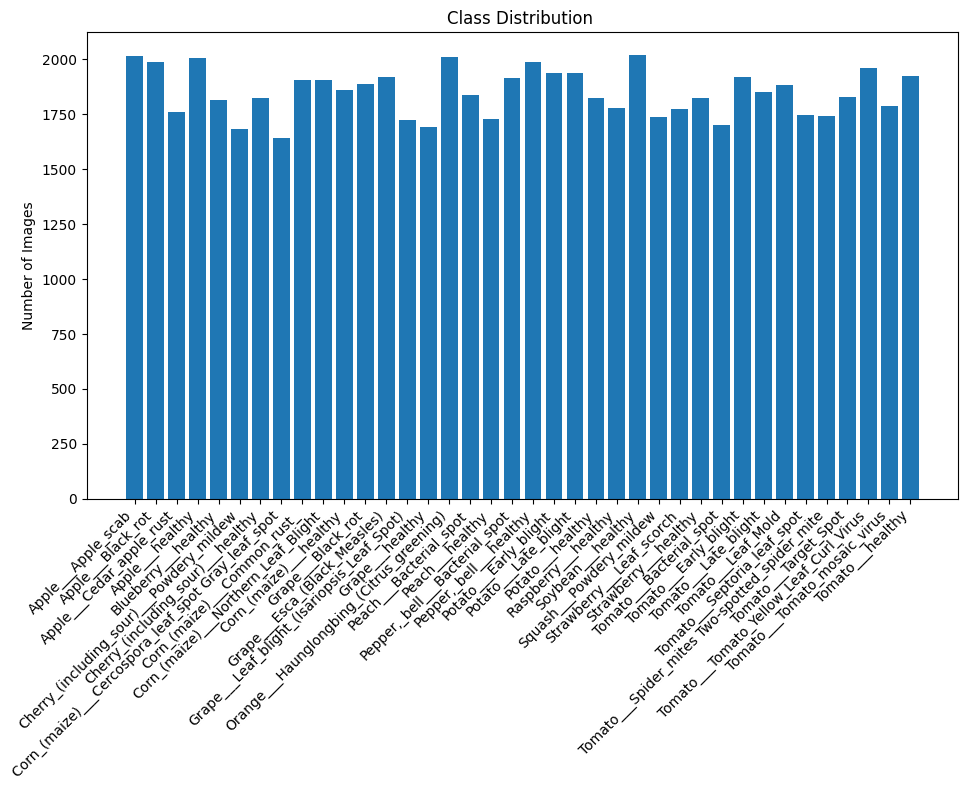

In [ ]:
import collections
import matplotlib.pyplot as plt
samples_per_class=collections.Counter()

for path,lb in train_dataset.samples:
  class_names=train_dataset.classes[lb]
  samples_per_class[class_names]+=1

class_count= {name:samples_per_class.get(name,0) for name in train_dataset.classes}
plt.figure(figsize=(10, 8))
plt.bar(samples_per_class.keys(),samples_per_class.values())
plt.xticks(rotation=45, ha='right')
plt.title("Class Distribution ")
plt.ylabel("Number of Images")
plt.tight_layout()
plt.show()













In [ ]:
BATCH_SIZE= 32
train_loader=DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=6,
    pin_memory=True

)

val_loader=DataLoader(
    valid_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=6,
    pin_memory=True
)

/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:627: UserWarning: This DataLoader will create 6 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(


In [ ]:
device= torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model= models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)

for param in model.parameters():
  param.requires_grad=False

num_features=model.fc.in_features
model.fc=nn.Linear(num_features,38)

model=model.to(device)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 190MB/s]


In [ ]:
import os, time, copy, pickle
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import models
from tqdm import tqdm

# ---------- Settings ----------
BATCH_SIZE = 32
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
NUM_EPOCHS = 10
LR = 1e-3
PATIENCE = 3
DRIVE_CHECKPOINT_DIR = "/content/drive/MyDrive/PlantDiseaseCheckpoints"
os.makedirs(DRIVE_CHECKPOINT_DIR, exist_ok=True)

# ---------- DataLoaders ----------
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=4,           # safer on Colab free GPU
    pin_memory=True,
    prefetch_factor=2
)

val_loader = DataLoader(
    valid_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=4,
    pin_memory=True,
    prefetch_factor=2
)

# ---------- Model ----------
model = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
for param in model.parameters():
    param.requires_grad = False
num_features = model.fc.in_features
model.fc = nn.Linear(num_features, 38)
model = model.to(DEVICE)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.fc.parameters(), lr=LR)
scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=4, gamma=0.1)
scaler = torch.cuda.amp.GradScaler()

# ---------- Training Loop ----------
def train_model(model, train_loader, val_loader, criterion, optimizer, scheduler,
                num_epochs, device, patience=3, resume_checkpoint=None):

    since = time.time()
    best_model_wts = copy.deepcopy(model.state_dict())
    best_val_loss = float('inf')
    counter = 0
    history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}
    start_epoch = 0

    # Resume checkpoint if provided
    if resume_checkpoint and os.path.exists(resume_checkpoint):
        print(f"Resuming from {resume_checkpoint}")
        checkpoint = torch.load(resume_checkpoint, map_location=device)
        model.load_state_dict(checkpoint['model_state_dict'])
        optimizer.load_state_dict(checkpoint['optimizer_state_dict'])
        scheduler.load_state_dict(checkpoint['scheduler_state_dict'])
        start_epoch = checkpoint['epoch'] + 1
        best_val_loss = checkpoint.get('best_val_loss', float('inf'))
        history = checkpoint.get('history', history)
        print(f"Resumed at epoch {start_epoch}")

    for epoch in range(start_epoch, num_epochs):
        print(f"\nEpoch {epoch+1}/{num_epochs}")

        # ---------- Train ----------
        model.train()
        running_loss, running_corrects, total = 0.0, 0, 0

        for inputs, labels in tqdm(train_loader, desc="Train"):
            inputs, labels = inputs.to(device, non_blocking=True), labels.to(device, non_blocking=True)
            optimizer.zero_grad()
            with torch.cuda.amp.autocast():
                outputs = model(inputs)
                loss = criterion(outputs, labels)

            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()

            running_loss += loss.item() * inputs.size(0)
            running_corrects += (outputs.argmax(1) == labels).sum().item()
            total += labels.size(0)

        train_loss = running_loss / total
        train_acc = running_corrects / total

        # ---------- Validation ----------
        model.eval()
        running_loss, running_corrects, total = 0.0, 0, 0
        with torch.no_grad():
            for inputs, labels in tqdm(val_loader, desc="Val"):
                inputs, labels = inputs.to(device, non_blocking=True), labels.to(device, non_blocking=True)
                with torch.cuda.amp.autocast():
                    outputs = model(inputs)
                    loss = criterion(outputs, labels)

                running_loss += loss.item() * inputs.size(0)
                running_corrects += (outputs.argmax(1) == labels).sum().item()
                total += labels.size(0)

        val_loss = running_loss / total
        val_acc = running_corrects / total

        history['train_loss'].append(train_loss)
        history['val_loss'].append(val_loss)
        history['train_acc'].append(train_acc)
        history['val_acc'].append(val_acc)

        print(f"Train Loss: {train_loss:.4f} | Acc: {train_acc:.4f}")
        print(f"Val   Loss: {val_loss:.4f} | Acc: {val_acc:.4f}")

        # ---------- Save best model ----------
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_model_wts = copy.deepcopy(model.state_dict())
            counter = 0
            torch.save(model.state_dict(), os.path.join(DRIVE_CHECKPOINT_DIR, "best_model.pth"))
            print("Best model updated & saved.")
        else:
            counter += 1

        # ---------- Early stopping ----------
        if counter >= patience:
            print("Early stopping triggered.")
            break

        scheduler.step()

    time_elapsed = time.time() - since
    print(f"\nTraining completed in {time_elapsed/60:.1f} minutes")
    model.load_state_dict(best_model_wts)
    return model, history

# ---------- Train ----------
model, history = train_model(
    model,
    train_loader,
    val_loader,
    criterion,
    optimizer,
    scheduler,
    NUM_EPOCHS,
    DEVICE,
    patience=PATIENCE
)

# ---------- Save history ----------
with open("/content/drive/MyDrive/history_v1.pkl", "wb") as f:
    pickle.dump(history, f)

print("Training complete. Model & history saved.")


/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:627: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(
/tmp/ipython-input-3179654682.py:48: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler()



Epoch 1/10


Train:   0%|          | 0/2197 [00:00<?, ?it/s]/tmp/ipython-input-3179654682.py:83: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():
Val:   0%|          | 0/550 [00:00<?, ?it/s]/tmp/ipython-input-3179654682.py:104: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():
Val: 100%|██████████| 550/550 [00:49<00:00, 11.17it/s]


Train Loss: 0.5540 | Acc: 0.8681
Val   Loss: 0.2294 | Acc: 0.9317
Best model updated & saved.

Epoch 2/10


Val: 100%|██████████| 550/550 [00:48<00:00, 11.42it/s]


...

Train Loss: 0.1423 | Acc: 0.9536
Val   Loss: 0.1331 | Acc: 0.9555
Best model updated & saved.

Epoch 9/10


Val: 100%|██████████| 550/550 [00:49<00:00, 11.20it/s]


Train Loss: 0.1381 | Acc: 0.9553
Val   Loss: 0.1315 | Acc: 0.9572
Best model updated & saved.

Epoch 10/10


Val: 100%|██████████| 550/550 [00:49<00:00, 11.01it/s]

Train Loss: 0.1379 | Acc: 0.9552
Val   Loss: 0.1319 | Acc: 0.9560

Training completed in 43.7 minutes
Training complete. Model & history saved.


model testing


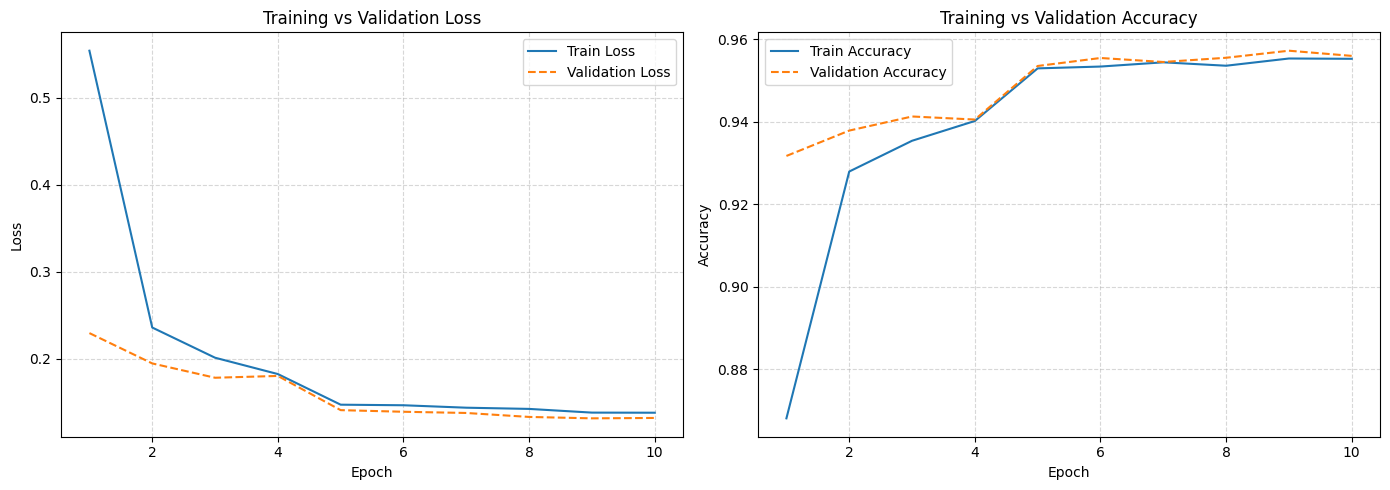

In [ ]:
import matplotlib.pyplot as plt

epochs = range(1, len(history['train_loss']) + 1)

plt.figure(figsize=(14, 5))

# -----------------------------
# Loss Plot
# -----------------------------
plt.subplot(1, 2, 1)
plt.plot(epochs, history['train_loss'], label='Train Loss')
plt.plot(epochs, history['val_loss'], label='Validation Loss', linestyle='--')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training vs Validation Loss')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)

# -----------------------------
# Accuracy Plot
# -----------------------------
plt.subplot(1, 2, 2)
plt.plot(epochs, history['train_acc'], label='Train Accuracy')
plt.plot(epochs, history['val_acc'], label='Validation Accuracy', linestyle='--')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Training vs Validation Accuracy')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()


fine tuned version of the model


In [ ]:
# Unfreeze layer4 only
for param in model.layer4.parameters():
    param.requires_grad = True


In [ ]:
FINE_TUNE_LR = 1e-4  # 10x smaller than before

optimizer_ft = optim.Adam(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=FINE_TUNE_LR
)


In [ ]:
scheduler_ft = optim.lr_scheduler.StepLR(
    optimizer_ft,
    step_size=3,
    gamma=0.1
)


In [ ]:
def fine_tune_model(
    model,
    train_loader,
    val_loader,
    criterion,
    optimizer,
    scheduler,
    num_epochs,
    device
):
    since = time.time()

    history_ft = {
        'train_loss': [],
        'val_loss': [],
        'train_acc': [],
        'val_acc': []
    }

    model.to(device)

    for epoch in range(num_epochs):
        print(f"\n[Fine-Tune] Epoch {epoch+1}/{num_epochs}")

        # ---------- Training ----------
        model.train()
        running_loss, running_corrects, total = 0.0, 0, 0

        for inputs, labels in tqdm(train_loader, desc="Fine-Tune Train"):
            inputs = inputs.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            optimizer.zero_grad()

            with torch.cuda.amp.autocast():
                outputs = model(inputs)
                loss = criterion(outputs, labels)

            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()

            running_loss += loss.item() * inputs.size(0)
            running_corrects += (outputs.argmax(1) == labels).sum().item()
            total += labels.size(0)

        train_loss = running_loss / total
        train_acc = running_corrects / total

        # ---------- Validation ----------
        model.eval()
        running_loss, running_corrects, total = 0.0, 0, 0

        with torch.no_grad():
            for inputs, labels in tqdm(val_loader, desc="Fine-Tune Val"):
                inputs = inputs.to(device, non_blocking=True)
                labels = labels.to(device, non_blocking=True)

                with torch.cuda.amp.autocast():
                    outputs = model(inputs)
                    loss = criterion(outputs, labels)

                running_loss += loss.item() * inputs.size(0)
                running_corrects += (outputs.argmax(1) == labels).sum().item()
                total += labels.size(0)

        val_loss = running_loss / total
        val_acc = running_corrects / total

        history_ft['train_loss'].append(train_loss)
        history_ft['val_loss'].append(val_loss)
        history_ft['train_acc'].append(train_acc)
        history_ft['val_acc'].append(val_acc)

        print(f"Train Loss: {train_loss:.4f} | Acc: {train_acc:.4f}")
        print(f"Val   Loss: {val_loss:.4f} | Acc: {val_acc:.4f}")

        scheduler.step()

    time_elapsed = time.time() - since
    print(f"\nFine-tuning completed in {time_elapsed/60:.1f} minutes")

    return model, history_ft


In [ ]:
FINE_TUNE_EPOCHS = 5

model, history_finetune = fine_tune_model(
    model,
    train_loader,
    val_loader,
    criterion,
    optimizer_ft,
    scheduler_ft,
    FINE_TUNE_EPOCHS,
    device
)



[Fine-Tune] Epoch 1/5


Fine-Tune Train:   0%|          | 0/2197 [00:00<?, ?it/s]/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:627: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(
/tmp/ipython-input-3174881395.py:35: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():
Fine-Tune Val:   0%|          | 0/550 [00:00<?, ?it/s]/tmp/ipython-input-3174881395.py:59: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():
Fine-Tune Val: 100%|██████████| 550/550 [00:47

Train Loss: 0.0982 | Acc: 0.9673
Val   Loss: 0.0515 | Acc: 0.9820

[Fine-Tune] Epoch 2/5


Fine-Tune Val: 100%|██████████| 550/550 [00:47<00:00, 11.47it/s]


Train Loss: 0.0407 | Acc: 0.9862
Val   Loss: 0.0374 | Acc: 0.9884

[Fine-Tune] Epoch 3/5


...

Train Loss: 0.0326 | Acc: 0.9891
Val   Loss: 0.0284 | Acc: 0.9908

[Fine-Tune] Epoch 4/5


Fine-Tune Val: 100%|██████████| 550/550 [00:47<00:00, 11.69it/s]


Train Loss: 0.0112 | Acc: 0.9967
Val   Loss: 0.0134 | Acc: 0.9954

[Fine-Tune] Epoch 5/5


Fine-Tune Val: 100%|██████████| 550/550 [00:47<00:00, 11.68it/s]

Train Loss: 0.0076 | Acc: 0.9975
Val   Loss: 0.0116 | Acc: 0.9963

Fine-tuning completed in 22.2 minutes


In [ ]:
torch.save(
    model.state_dict(),
    "/content/drive/MyDrive/crop_disease_detection_v1_finetuned.pth"
)


In [ ]:
import pickle

# Save fine-tuned training history
with open("/content/drive/MyDrive/history_finetuned.pkl", "wb") as f:
    pickle.dump(history_finetune, f)

print("Fine-tuned history saved as history_finetuned.pkl")


Fine-tuned history saved as history_finetuned.pkl


Evaluating:   0%|          | 0/550 [00:00<?, ?it/s]/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:627: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(


Validation Accuracy: 99.6301%


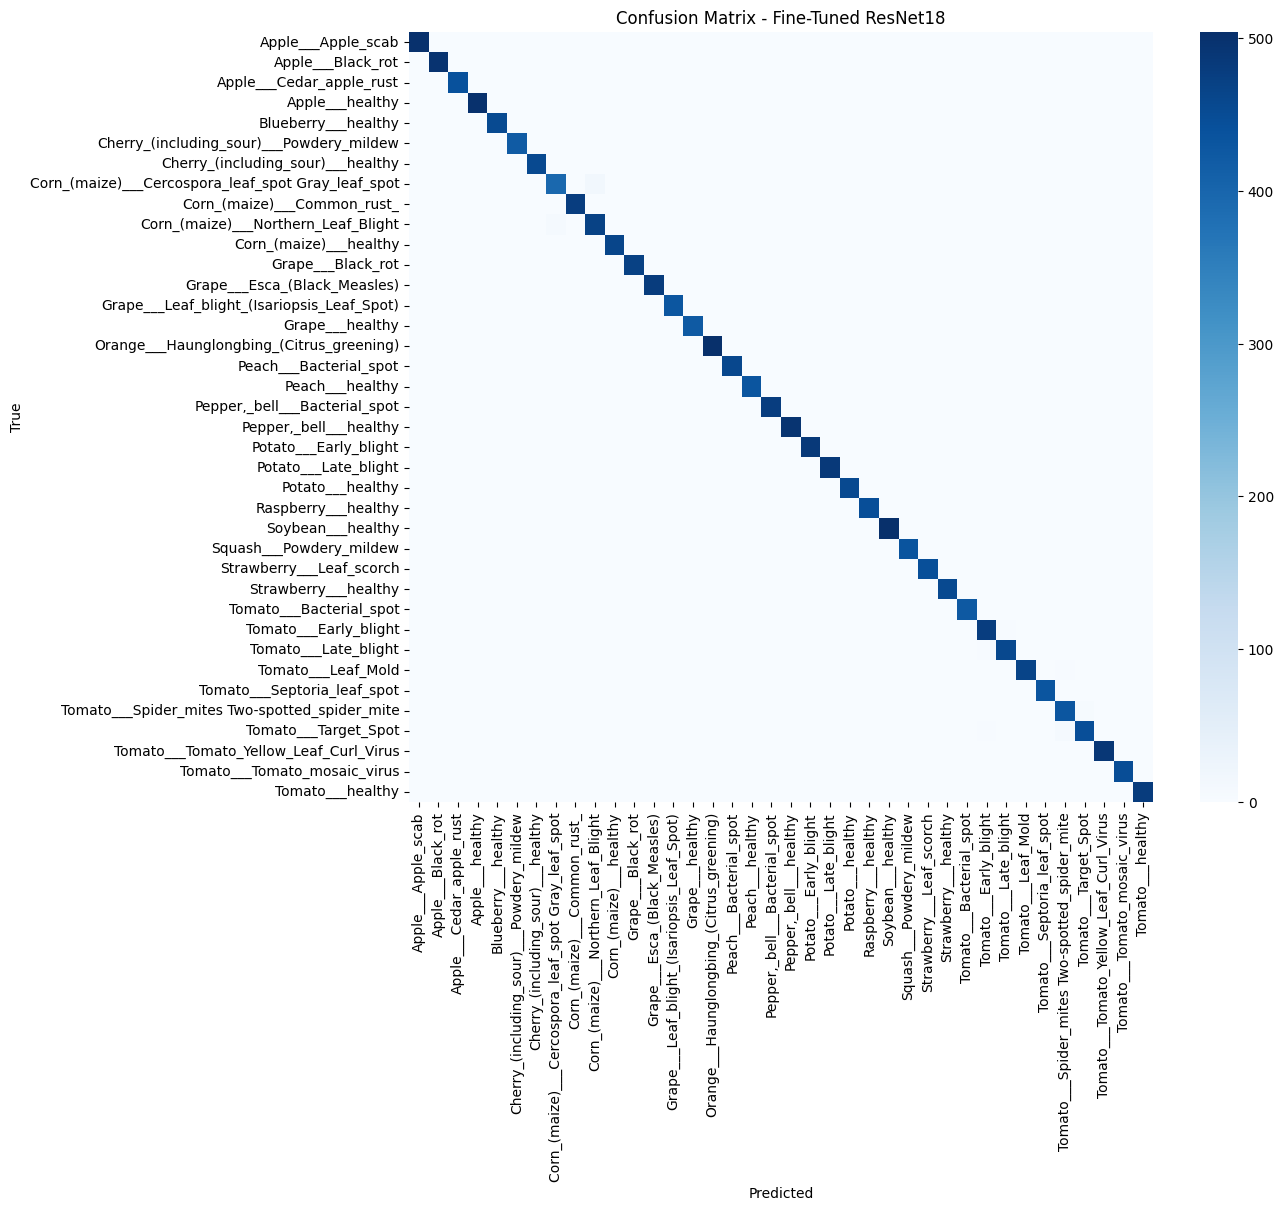


Classification Report:
                                                    precision    recall  f1-score   support

                                Apple___Apple_scab       1.00      1.00      1.00       504
                                 Apple___Black_rot       1.00      1.00      1.00       497
                          Apple___Cedar_apple_rust       1.00      1.00      1.00       440
                                   Apple___healthy       1.00      1.00      1.00       502
                               Blueberry___healthy       1.00      1.00      1.00       454
          Cherry_(including_sour)___Powdery_mildew       1.00      1.00      1.00       421
                 Cherry_(including_sour)___healthy       1.00      1.00      1.00       456
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot       0.98      0.96      0.97       410
                       Corn_(maize)___Common_rust_       1.00      1.00      1.00       477
               Corn_(maize)___Northern_Leaf_Blight     

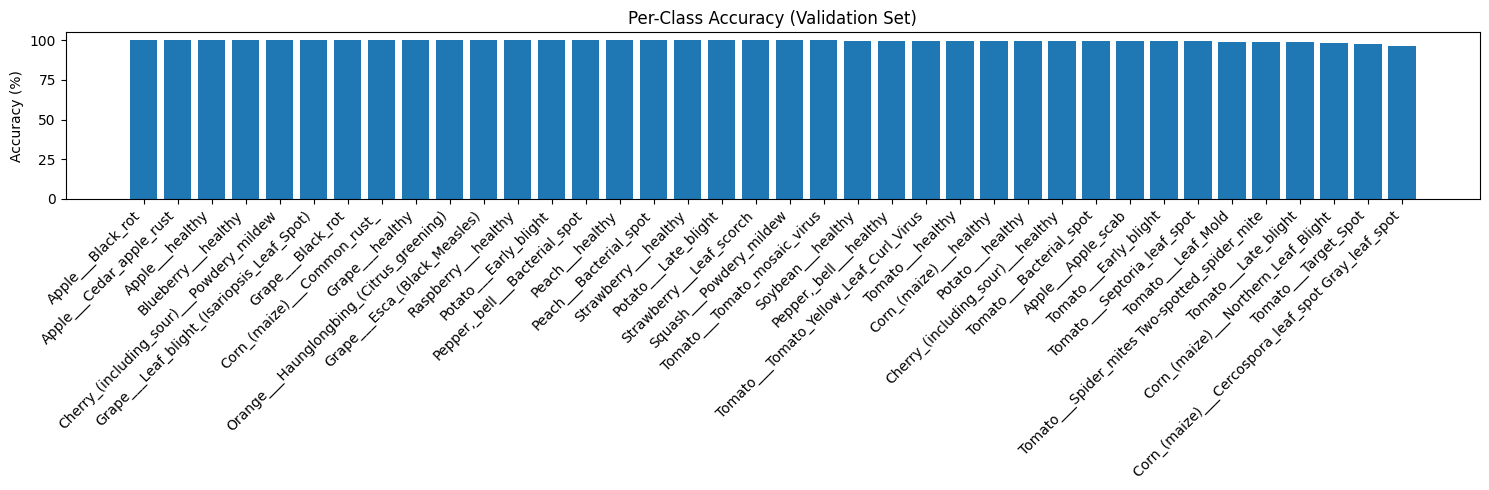

In [ ]:
# -----------------------------
# Evaluation on Validation Set
# -----------------------------
import torch
import numpy as np
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm

def evaluate_model(model, loader, device='cuda'):
    """
    Evaluate model on a given DataLoader.

    Returns:
        overall_acc : float
        y_true : np.array
        y_pred : np.array
    """
    model.eval()
    all_preds, all_labels = [], []

    with torch.no_grad():
        for inputs, labels in tqdm(loader, desc='Evaluating', leave=False):
            inputs, labels = inputs.to(device), labels.to(device)

            outputs = model(inputs)
            preds = outputs.argmax(dim=1)

            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    overall_acc = accuracy_score(all_labels, all_preds)
    return overall_acc, np.array(all_labels), np.array(all_preds)


# -----------------------------
# Run evaluation
# -----------------------------
val_acc, y_true, y_pred = evaluate_model(model, val_loader, device=device)
print(f"Validation Accuracy: {val_acc:.4%}")

# -----------------------------
# Confusion Matrix
# -----------------------------
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(12, 10))
sns.heatmap(cm, annot=False, fmt="d",
            xticklabels=valid_dataset.classes,
            yticklabels=valid_dataset.classes,
            cmap="Blues")
plt.title("Confusion Matrix - Fine-Tuned ResNet18")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.show()

# -----------------------------
# Classification Report
# -----------------------------
print("\nClassification Report:")
print(classification_report(y_true, y_pred, target_names=valid_dataset.classes))

# -----------------------------
# Per-Class Accuracy
# -----------------------------
class_correct = np.diag(cm)
class_totals = cm.sum(axis=1)
class_accuracy = class_correct / class_totals * 100

# Sort by accuracy for better visualization
sorted_idx = np.argsort(-class_accuracy)
sorted_classes = [valid_dataset.classes[i] for i in sorted_idx]
sorted_acc = class_accuracy[sorted_idx]

plt.figure(figsize=(15, 5))
plt.bar(sorted_classes, sorted_acc)
plt.xticks(rotation=45, ha='right')
plt.ylabel("Accuracy (%)")
plt.title("Per-Class Accuracy (Validation Set)")
plt.tight_layout()
plt.show()
